# Initial EDA - Weather Station Measurements

This notebook explores the weather-station data from **2026-01-01 to 2026-05-01**.

Main goal for now: understand the data before building any prediction model.

## 1. Setup

Import the packages and load the source CSV. The file uses semicolons as separators and `cp1252` encoding for symbols like ° and ².

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

DATA_PATH = Path("20260101_20260501_Weather_Station_Measurements.csv")

raw = pd.read_csv(DATA_PATH, sep=";", encoding="cp1252")
raw.head()

,Date,Time,AIR TEMPERATURE (°C),BAROMETRIC PRESSURE (mbar),PRECIPITATION (mm),PYRANOMETER (W/m²),RH (% RH),STRIKES,WIND DIRECTION (°),WIND GUST (m/s),WIND SPEED (m/s)
0,01/01/26,00:00,0.3,1018.0,0.0,0.0,47.7,0,354.5,8.7,4.1
1,01/01/26,00:10,0.2,1018.2,0.0,0.0,48.5,0,356.7,8.4,3.5
2,01/01/26,00:20,0.2,1018.1,0.0,0.0,47.9,0,345.4,7.4,4.0
3,01/01/26,00:30,0.2,1018.2,0.0,0.0,48.2,0,345.8,9.5,4.7
4,01/01/26,00:40,-0.1,1018.2,0.0,0.0,49.8,0,348.3,6.9,3.6


In [6]:
raw.shape

(17277, 11)

In [7]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17277 entries, 0 to 17276
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        17277 non-null  object 
 1   Time                        17277 non-null  object 
 2   AIR TEMPERATURE (°C)        17277 non-null  float64
 3   BAROMETRIC PRESSURE (mbar)  17277 non-null  float64
 4   PRECIPITATION (mm)          17277 non-null  object 
 5   PYRANOMETER (W/m²)          17277 non-null  object 
 6   RH (% RH)                   17277 non-null  float64
 7   STRIKES                     17277 non-null  object 
 8   WIND DIRECTION (°)          17277 non-null  object 
 9   WIND GUST (m/s)             17277 non-null  object 
 10  WIND SPEED (m/s)            17277 non-null  object 
dtypes: float64(3), object(8)
memory usage: 1.5+ MB


## 2. Clean Column Names And Build Timestamp

The original names are readable, but shorter snake_case names make analysis easier. We also combine `Date` and `Time` into one timestamp column.

In [9]:
df = raw.copy()

column_map = {
    "Date": "date",
    "Time": "time",
    "AIR TEMPERATURE (°C)": "air_temperature_c",
    "BAROMETRIC PRESSURE (mbar)": "barometric_pressure_mbar",
    "PRECIPITATION (mm)": "precipitation_mm",
    "PYRANOMETER (W/m²)": "pyranometer_w_m2",
    "RH (% RH)": "relative_humidity_percent",
    "STRIKES": "strikes",
    "WIND DIRECTION (°)": "wind_direction_deg",
    "WIND GUST (m/s)": "wind_gust_m_s",
    "WIND SPEED (m/s)": "wind_speed_m_s",
}

df = df.rename(columns=column_map)
df["timestamp"] = pd.to_datetime(df["date"] + " " + df["time"], format="%d/%m/%y %H:%M", errors="coerce")

df = df.sort_values("timestamp").reset_index(drop=True)
df = df[["timestamp"] + [col for col in df.columns if col != "timestamp"]]

df.head()

,timestamp,date,time,air_temperature_c,barometric_pressure_mbar,precipitation_mm,pyranometer_w_m2,relative_humidity_percent,strikes,wind_direction_deg,wind_gust_m_s,wind_speed_m_s
0,2026-01-01 00:00:00,01/01/26,00:00,0.3,1018.0,0.0,0.0,47.7,0,354.5,8.7,4.1
1,2026-01-01 00:10:00,01/01/26,00:10,0.2,1018.2,0.0,0.0,48.5,0,356.7,8.4,3.5
2,2026-01-01 00:20:00,01/01/26,00:20,0.2,1018.1,0.0,0.0,47.9,0,345.4,7.4,4.0
3,2026-01-01 00:30:00,01/01/26,00:30,0.2,1018.2,0.0,0.0,48.2,0,345.8,9.5,4.7
4,2026-01-01 00:40:00,01/01/26,00:40,-0.1,1018.2,0.0,0.0,49.8,0,348.3,6.9,3.6


In [10]:
measurement_cols = [
    "air_temperature_c",
    "barometric_pressure_mbar",
    "precipitation_mm",
    "pyranometer_w_m2",
    "relative_humidity_percent",
    "strikes",
    "wind_direction_deg",
    "wind_gust_m_s",
    "wind_speed_m_s",
]

# Make sure measurement columns are numeric.
for col in measurement_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[measurement_cols].head()

,air_temperature_c,barometric_pressure_mbar,precipitation_mm,pyranometer_w_m2,relative_humidity_percent,strikes,wind_direction_deg,wind_gust_m_s,wind_speed_m_s
0,0.3,1018.0,0.0,0.0,47.7,0.0,354.5,8.7,4.1
1,0.2,1018.2,0.0,0.0,48.5,0.0,356.7,8.4,3.5
2,0.2,1018.1,0.0,0.0,47.9,0.0,345.4,7.4,4.0
3,0.2,1018.2,0.0,0.0,48.2,0.0,345.8,9.5,4.7
4,-0.1,1018.2,0.0,0.0,49.8,0.0,348.3,6.9,3.6


## 3. Time Coverage And Sampling Interval

This checks how much data we have, whether timestamps are duplicated, and whether readings arrive every 10 minutes as expected.

In [12]:
time_summary = pd.DataFrame({
    "rows": [len(df)],
    "start_time": [df["timestamp"].min()],
    "end_time": [df["timestamp"].max()],
    "duration": [df["timestamp"].max() - df["timestamp"].min()],
    "duplicate_timestamps": [df["timestamp"].duplicated().sum()],
    "missing_timestamps": [df["timestamp"].isna().sum()],
})

time_summary

,rows,start_time,end_time,duration,duplicate_timestamps,missing_timestamps
0,17277,2026-01-01,2026-05-01 01:00:00,120 days 01:00:00,0,0


In [13]:
interval_counts = df["timestamp"].diff().value_counts().sort_index()
interval_counts

timestamp
0 days 00:10:00    17271
0 days 00:20:00        4
0 days 01:10:00        1
Name: count, dtype: int64

## 4. Missing Values

Missingness tells us whether a sensor was unavailable or whether some measurements need cleaning before modeling.

In [15]:
missing = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100,
    })
    .sort_values("missing_percent", ascending=False)
)

missing

,missing_count,missing_percent
wind_direction_deg,175,1.012907
wind_speed_m_s,50,0.289402
wind_gust_m_s,48,0.277826
precipitation_mm,2,0.011576
pyranometer_w_m2,2,0.011576
strikes,2,0.011576
timestamp,0,0.000000
date,0,0.000000
time,0,0.000000
air_temperature_c,0,0.000000


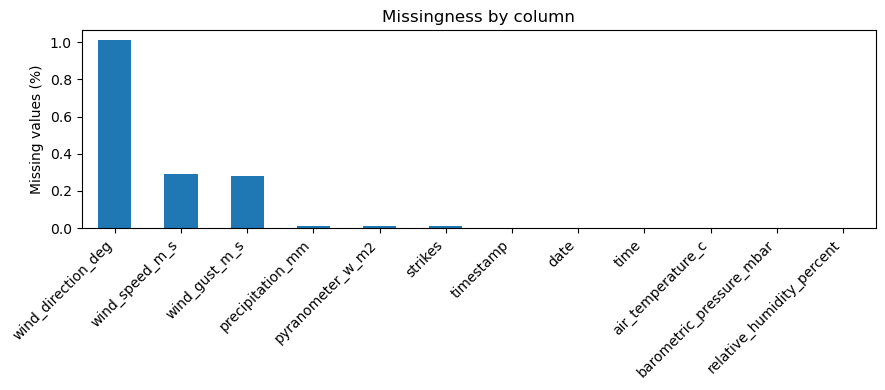

In [16]:
plt.figure(figsize=(9, 4))
missing["missing_percent"].plot(kind="bar")
plt.ylabel("Missing values (%)")
plt.title("Missingness by column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Descriptive Statistics

This gives basic ranges for every numeric measurement. Use it to spot impossible or suspicious values.

In [18]:
df[measurement_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
air_temperature_c,17277.0,10.632581,5.162532,-5.4,-1.5,1.900,7.5,10.6,14.0,19.200,23.200,28.1
barometric_pressure_mbar,17277.0,1012.540343,9.478286,985.1,989.5,996.400,1006.2,1013.1,1019.3,1027.200,1031.024,1033.9
precipitation_mm,17275.0,0.010802,0.048650,0.0,0.0,0.000,0.0,0.0,0.0,0.100,0.200,1.3
pyranometer_w_m2,17275.0,117.152706,188.811669,0.0,0.0,0.000,0.0,0.0,178.0,557.000,723.000,880.0
relative_humidity_percent,17277.0,82.400550,15.302659,25.3,41.1,52.600,72.2,85.5,96.0,100.000,100.000,100.0
strikes,17275.0,0.013893,0.219289,0.0,0.0,0.000,0.0,0.0,0.0,0.000,0.000,13.0
wind_direction_deg,17102.0,196.498345,127.745210,0.0,1.1,7.205,68.2,229.8,319.5,353.595,357.900,359.0
wind_gust_m_s,17229.0,3.235144,2.792673,0.2,0.6,0.800,1.4,2.3,4.0,8.900,14.300,29.6
wind_speed_m_s,17227.0,1.530922,1.301494,0.1,0.3,0.400,0.7,1.1,1.8,4.200,6.800,9.7


In [19]:
quality_checks = pd.DataFrame({
    "check": [
        "temperature below -40 C",
        "temperature above 60 C",
        "relative humidity below 0%",
        "relative humidity above 100%",
        "negative precipitation",
        "negative pyranometer",
        "pyranometer above 1400 W/m2",
        "wind direction below 0 deg",
        "wind direction above 360 deg",
        "negative wind speed",
        "wind gust lower than wind speed",
    ],
    "count": [
        (df["air_temperature_c"] < -40).sum(),
        (df["air_temperature_c"] > 60).sum(),
        (df["relative_humidity_percent"] < 0).sum(),
        (df["relative_humidity_percent"] > 100).sum(),
        (df["precipitation_mm"] < 0).sum(),
        (df["pyranometer_w_m2"] < 0).sum(),
        (df["pyranometer_w_m2"] > 1400).sum(),
        (df["wind_direction_deg"] < 0).sum(),
        (df["wind_direction_deg"] > 360).sum(),
        (df["wind_speed_m_s"] < 0).sum(),
        (df["wind_gust_m_s"] < df["wind_speed_m_s"]).sum(),
    ]
})

quality_checks

,check,count
0,temperature below -40 C,0
1,temperature above 60 C,0
2,relative humidity below 0%,0
3,relative humidity above 100%,0
4,negative precipitation,0
5,negative pyranometer,0
6,pyranometer above 1400 W/m2,0
7,wind direction below 0 deg,0
8,wind direction above 360 deg,0
9,negative wind speed,0


## 6. Time-Series Plots

Plot every measurement against time. This is usually where sensor dropouts, weather cycles, and suspicious jumps become visible.

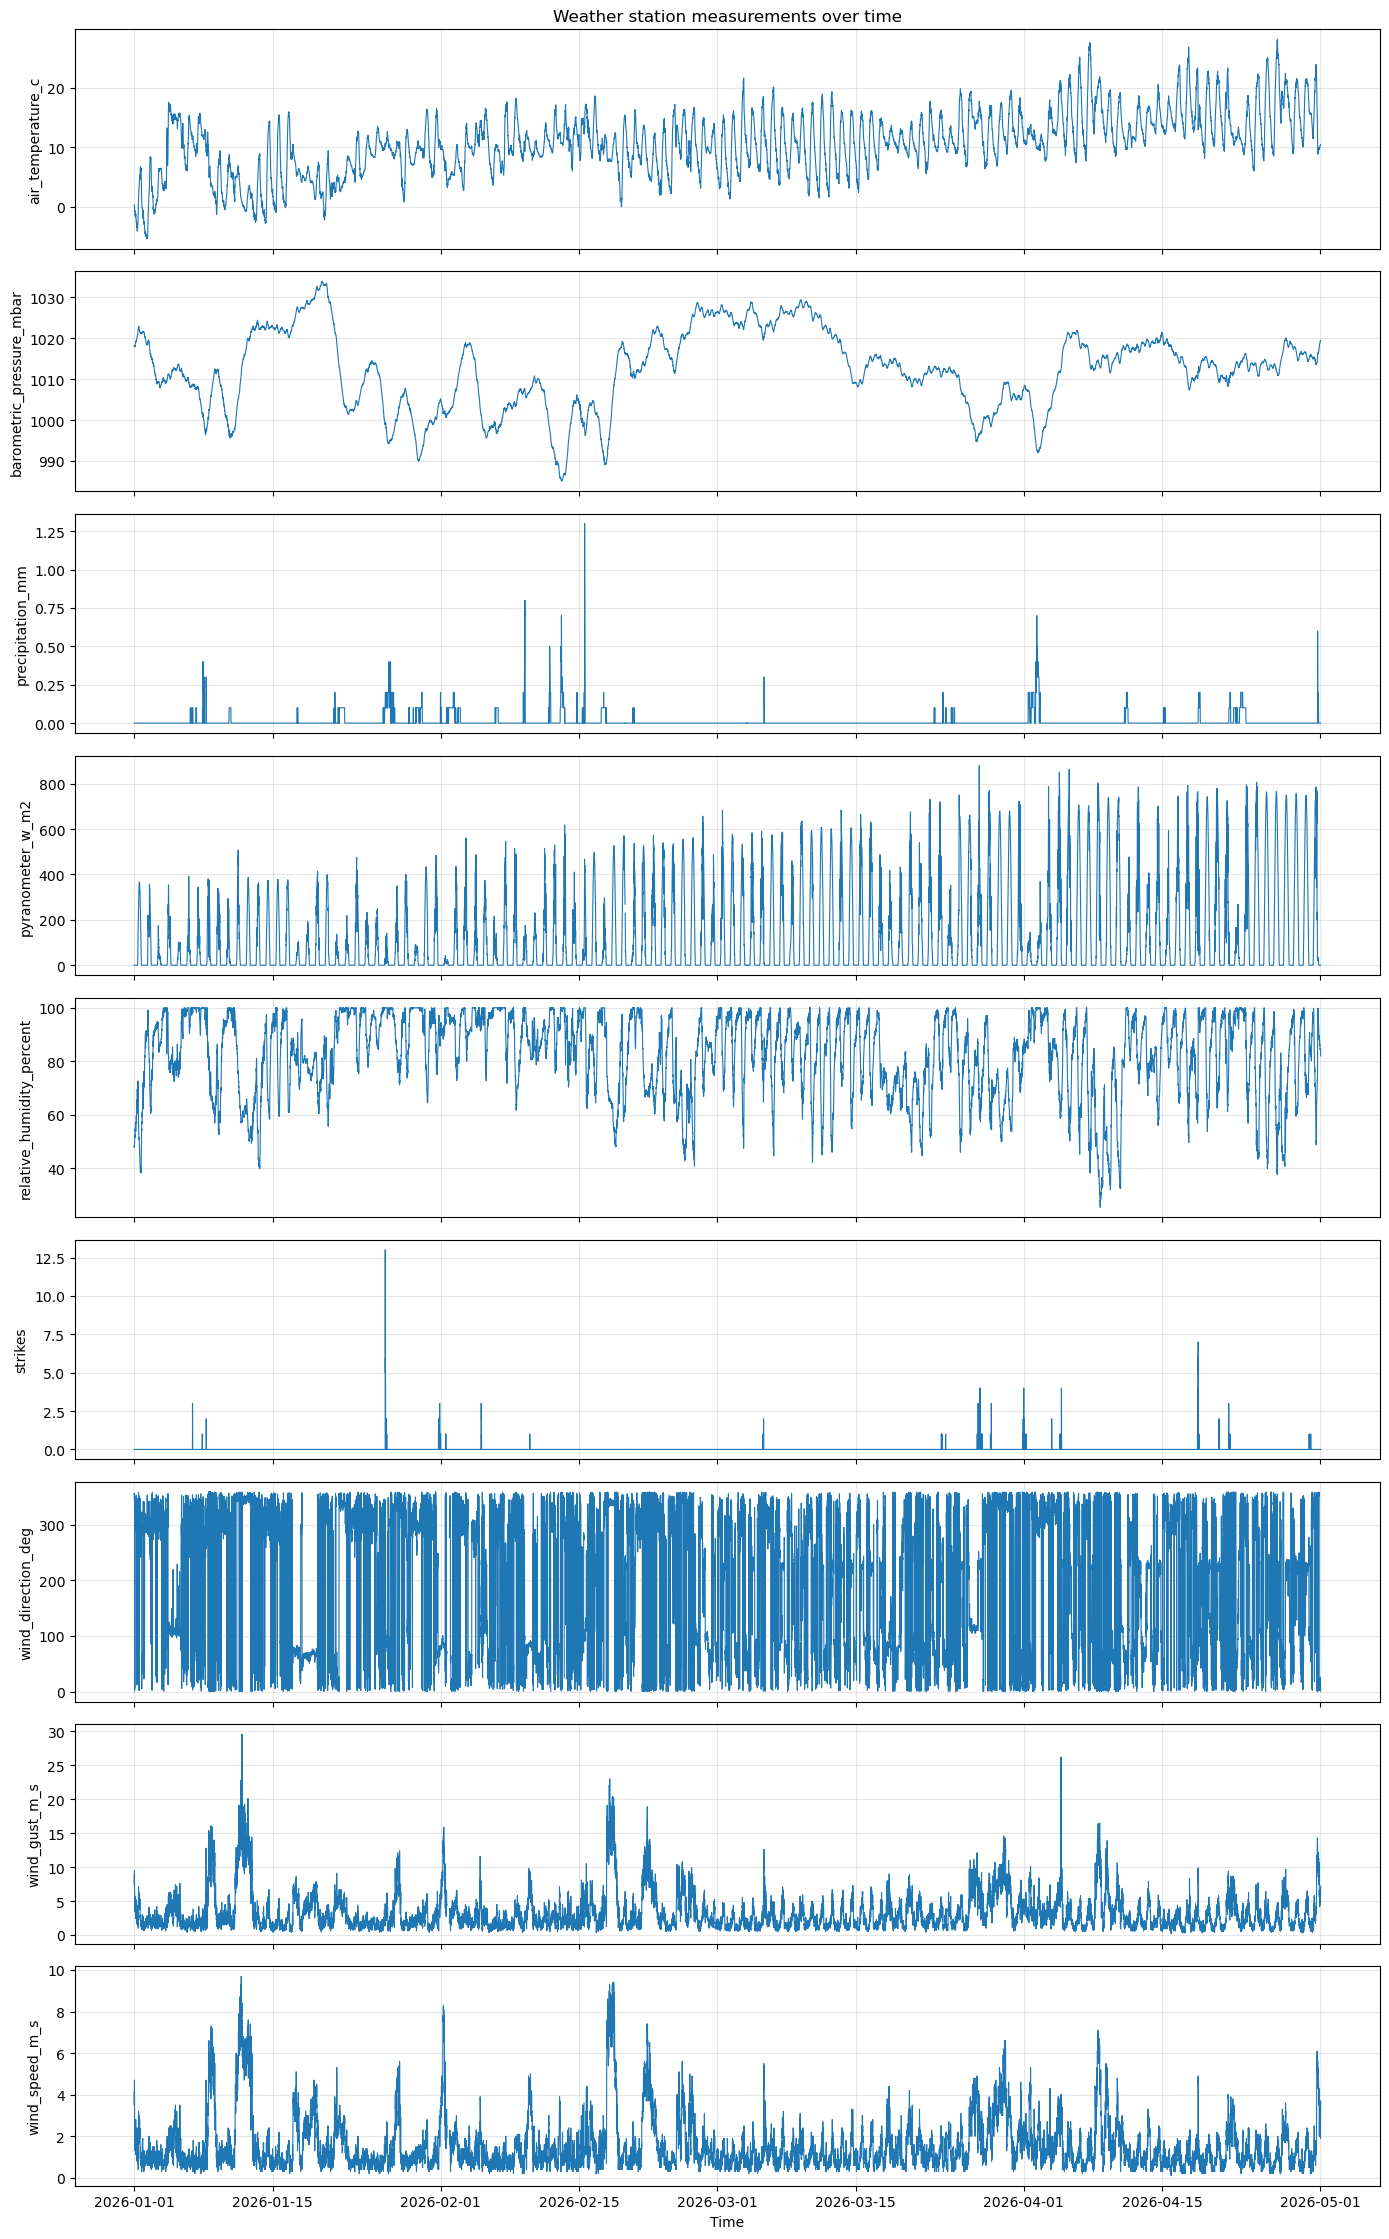

In [21]:
fig, axes = plt.subplots(len(measurement_cols), 1, figsize=(14, 2.5 * len(measurement_cols)), sharex=True)

for ax, col in zip(axes, measurement_cols):
    ax.plot(df["timestamp"], df[col], linewidth=0.8)
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[0].set_title("Weather station measurements over time")
axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

## 7. Daily Summary

Daily averages smooth the 10-minute noise and help reveal broad changes across months.

In [23]:
daily = df.set_index("timestamp")[measurement_cols].resample("D").agg(["mean", "min", "max"])
daily.head()

air_temperature_c            barometric_pressure_mbar                 precipitation_mm           pyranometer_w_m2              \
                        mean  min   max                     mean     min     max             mean  min  max             mean  min    max   
timestamp                                                                                                                                  
2026-01-01          0.369444 -4.1   6.7              1020.775694  1017.9  1022.9              0.0  0.0  0.0        86.326389  0.0  367.0   
2026-01-02          0.174306 -5.4   8.4              1017.383333  1013.0  1021.5              0.0  0.0  0.0        66.472222  0.0  357.0   
2026-01-03          3.095105 -1.2   6.5              1009.630070  1007.9  1012.9              0.0  0.0  0.0        17.335664  0.0  175.0   
2026-01-04         11.397222  2.7  17.5              1010.621528  1009.0  1012.7              0.0  0.0  0.0        53.909722  0.0  354.0   
2026-01-05         14.070833  9.8  15.7              1012.365972  1010.5  1013.7              0.0  0.0  0.0        20.805556  0.0  102.0   

           relative_humidity_percent              strikes           wind_direction_deg              wind_gust_m_s            \
                                mean   min    max    mean  min  max               mean   min    max          mean  min  max   
timestamp                                                                                                                     
2026-01-01                 56.108333  38.1   76.1     0.0  0.0  0.0         262.323611   0.8  358.1      3.222917  0.6  9.5   
2026-01-02                 81.346528  60.5   99.1     0.0  0.0  0.0         269.790278   2.3  358.5      1.945139  0.7  4.1   
2026-01-03                 91.497203  83.3   99.7     0.0  0.0  0.0         275.034266   0.6  354.5      1.786014  0.7  4.2   
2026-01-04                 86.878472  74.8  100.0     0.0  0.0  0.0         172.908333  12.0  356.0      3.311111  0.6  6.3   
2026-01-05                 82.866667  72.4   99.6     0.0  0.0  0.0         136.127083   5.7  353.1      3.430556  0.8  7.6   

           wind_speed_m_s            
                     mean  min  max  
timestamp                            
2026-01-01       1.550000  0.3  4.7  
2026-01-02       0.943750  0.4  2.0  
2026-01-03       0.869231  0.3  1.8  
2026-01-04       1.361806  0.3  2.5  
2026-01-05       1.536111  0.4  3.5

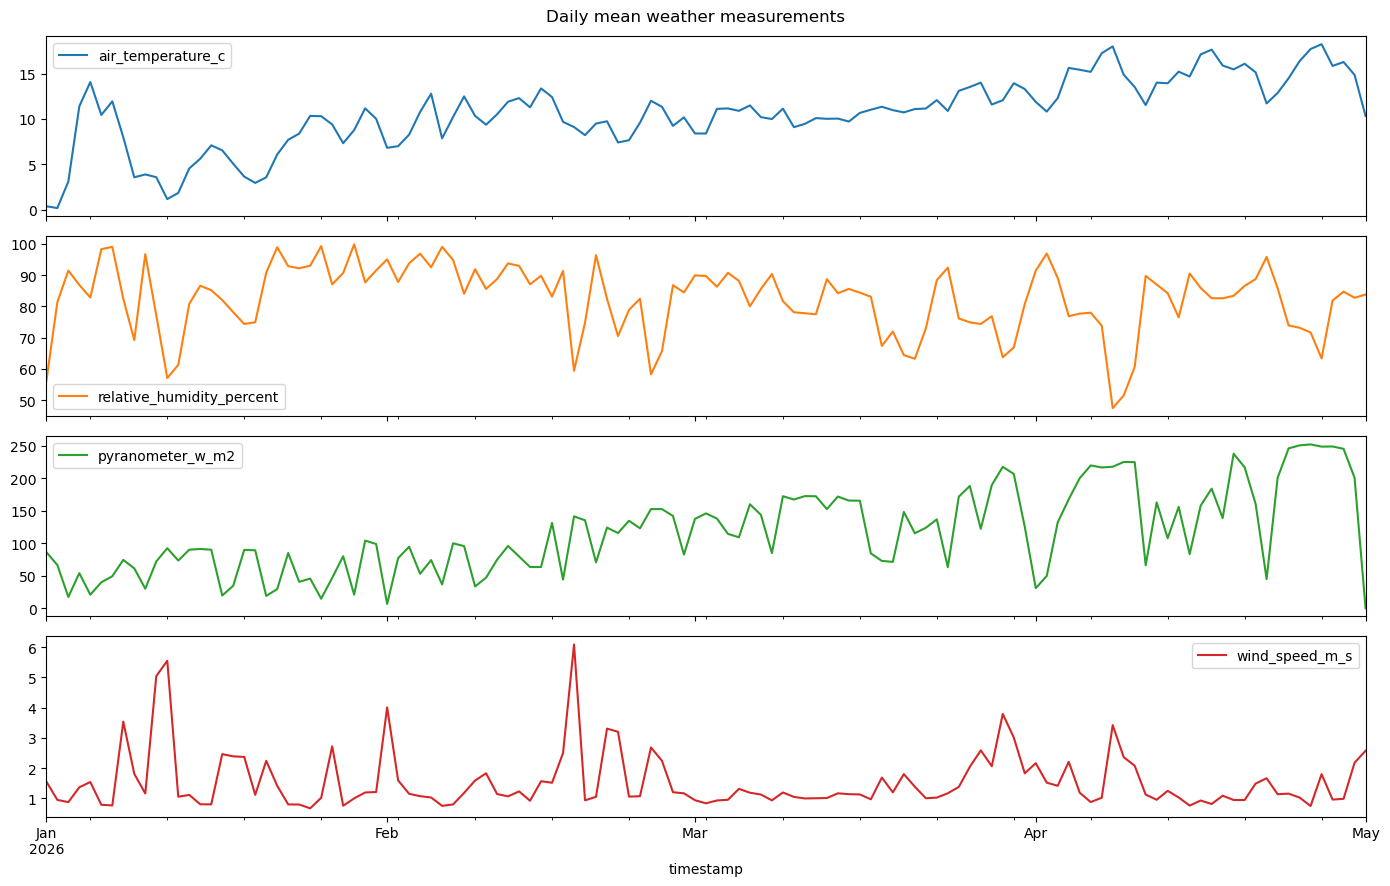

In [24]:
daily_mean = df.set_index("timestamp")[measurement_cols].resample("D").mean()

daily_mean[["air_temperature_c", "relative_humidity_percent", "pyranometer_w_m2", "wind_speed_m_s"]].plot(
    subplots=True,
    figsize=(14, 9),
    linewidth=1.5,
    title="Daily mean weather measurements",
)
plt.tight_layout()
plt.show()

## 8. Hourly Profile

Average by hour of day to see daily cycles: sunlight, temperature rise/fall, humidity changes, and wind patterns.

In [26]:
df["hour"] = df["timestamp"].dt.hour
hourly = df.groupby("hour")[measurement_cols].mean()
hourly

,air_temperature_c,barometric_pressure_mbar,precipitation_mm,pyranometer_w_m2,relative_humidity_percent,strikes,wind_direction_deg,wind_gust_m_s,wind_speed_m_s
hour,,,,,,,,,
0,8.904545,1013.002342,0.011019,0.000000,86.739394,0.016529,161.783518,2.508402,1.265427
1,8.445076,1012.850902,0.009709,0.000000,87.747157,0.004161,169.242340,2.549792,1.284882
2,8.122639,1012.750556,0.007778,0.000000,88.119583,0.012500,187.852786,2.620556,1.301528
3,7.784034,1012.638515,0.007563,0.000000,88.903782,0.001401,191.482386,2.611485,1.308403
4,7.478581,1012.372323,0.008345,0.000000,89.018220,0.000000,204.160335,2.736718,1.350626
5,7.260278,1012.304722,0.012083,0.000000,89.352222,0.002778,212.866014,2.789306,1.382778
6,7.045972,1012.356944,0.012361,0.490278,89.711667,0.005556,213.798034,2.746667,1.362500
7,7.107917,1012.562222,0.014583,19.643056,90.226528,0.002778,223.180979,2.824444,1.386944
8,7.939583,1012.884028,0.012500,89.300000,91.119583,0.000000,239.841036,3.072361,1.503333


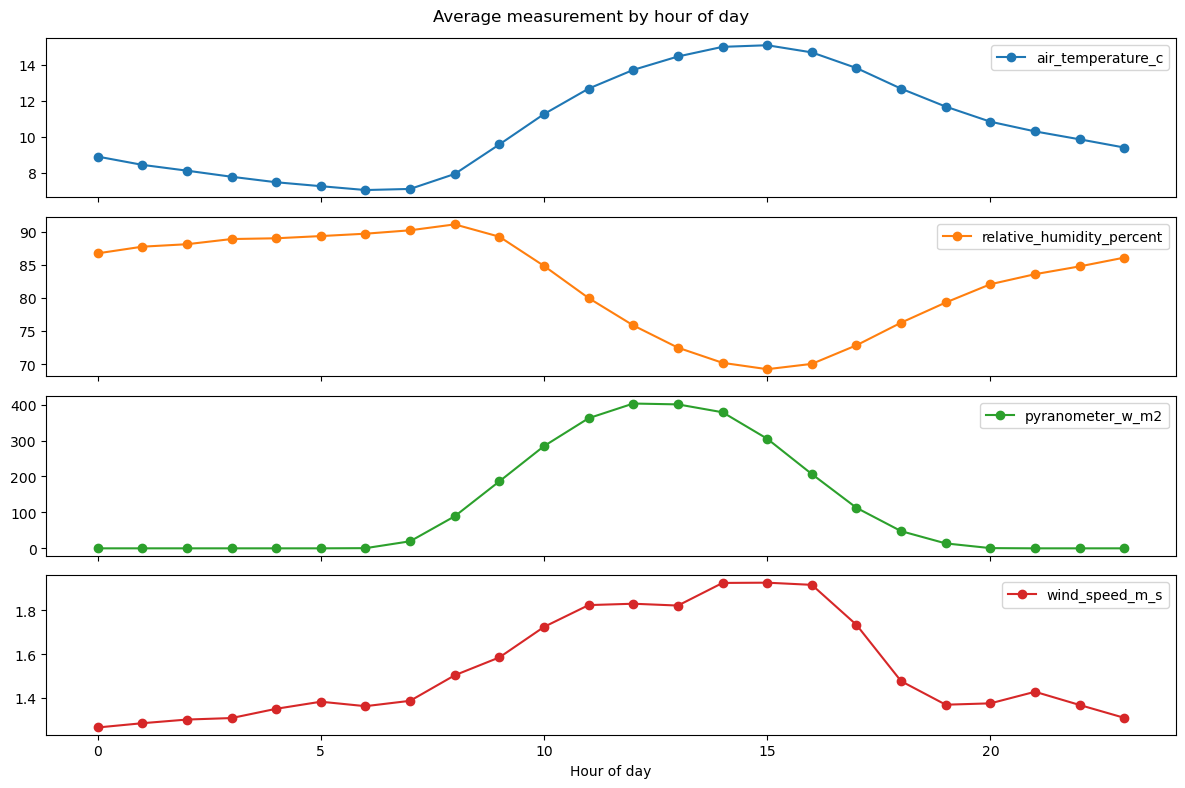

In [27]:
hourly[["air_temperature_c", "relative_humidity_percent", "pyranometer_w_m2", "wind_speed_m_s"]].plot(
    subplots=True,
    figsize=(12, 8),
    marker="o",
    title="Average measurement by hour of day",
)
plt.xlabel("Hour of day")
plt.tight_layout()
plt.show()

## 9. Correlation Between Measurements

Correlation helps us understand which measurements move together. Pearson checks linear relationships; Spearman checks monotonic/rank relationships.

In [29]:
pearson_corr = df[measurement_cols].corr(method="pearson")
spearman_corr = df[measurement_cols].corr(method="spearman")

pearson_corr

,air_temperature_c,barometric_pressure_mbar,precipitation_mm,pyranometer_w_m2,relative_humidity_percent,strikes,wind_direction_deg,wind_gust_m_s,wind_speed_m_s
air_temperature_c,1.000000,-0.127485,-0.025093,0.556053,-0.405052,0.043302,-0.098338,0.073374,0.011292
barometric_pressure_mbar,-0.127485,1.000000,-0.258410,0.087427,-0.215126,-0.050255,-0.095253,-0.109270,-0.092330
precipitation_mm,-0.025093,-0.258410,1.000000,-0.081476,0.226826,0.045080,-0.004354,-0.019759,-0.018722
pyranometer_w_m2,0.556053,0.087427,-0.081476,1.000000,-0.459977,0.000746,0.113904,0.226129,0.169010
relative_humidity_percent,-0.405052,-0.215126,0.226826,-0.459977,1.000000,0.006179,0.031837,-0.467861,-0.430182
strikes,0.043302,-0.050255,0.045080,0.000746,0.006179,1.000000,-0.009410,0.033584,0.033023
wind_direction_deg,-0.098338,-0.095253,-0.004354,0.113904,0.031837,-0.009410,1.000000,0.075085,0.048912
wind_gust_m_s,0.073374,-0.109270,-0.019759,0.226129,-0.467861,0.033584,0.075085,1.000000,0.969002
wind_speed_m_s,0.011292,-0.092330,-0.018722,0.169010,-0.430182,0.033023,0.048912,0.969002,1.000000


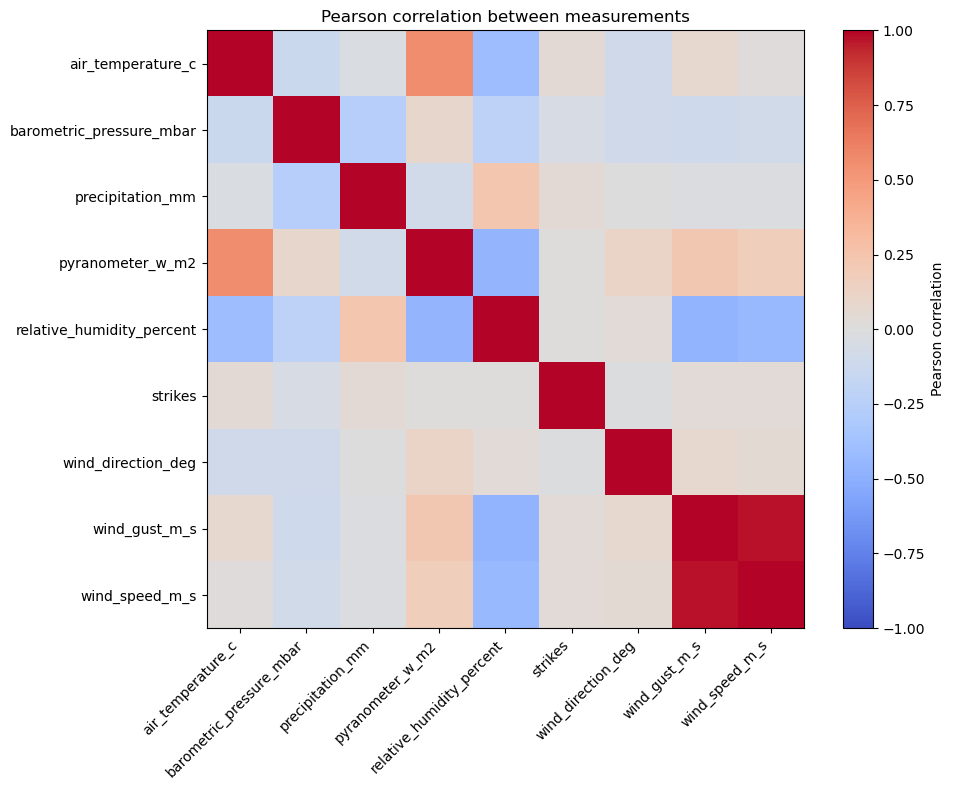

In [30]:
plt.figure(figsize=(10, 8))
plt.imshow(pearson_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(measurement_cols)), measurement_cols, rotation=45, ha="right")
plt.yticks(range(len(measurement_cols)), measurement_cols)
plt.title("Pearson correlation between measurements")
plt.tight_layout()
plt.show()

In [31]:
spearman_corr

,air_temperature_c,barometric_pressure_mbar,precipitation_mm,pyranometer_w_m2,relative_humidity_percent,strikes,wind_direction_deg,wind_gust_m_s,wind_speed_m_s
air_temperature_c,1.000000,-0.106903,-0.059557,0.508608,-0.407230,0.061943,-0.087177,0.247821,0.169571
barometric_pressure_mbar,-0.106903,1.000000,-0.245114,0.049209,-0.235809,-0.073066,-0.099136,-0.110050,-0.086601
precipitation_mm,-0.059557,-0.245114,1.000000,-0.060005,0.336555,0.056195,0.003440,0.037380,0.038006
pyranometer_w_m2,0.508608,0.049209,-0.060005,1.000000,-0.342933,0.013431,0.125474,0.385777,0.316880
relative_humidity_percent,-0.407230,-0.235809,0.336555,-0.342933,1.000000,-0.003055,0.039789,-0.495741,-0.459658
strikes,0.061943,-0.073066,0.056195,0.013431,-0.003055,1.000000,-0.012089,0.066930,0.066882
wind_direction_deg,-0.087177,-0.099136,0.003440,0.125474,0.039789,-0.012089,1.000000,0.092193,0.059681
wind_gust_m_s,0.247821,-0.110050,0.037380,0.385777,-0.495741,0.066930,0.092193,1.000000,0.961228
wind_speed_m_s,0.169571,-0.086601,0.038006,0.316880,-0.459658,0.066882,0.059681,0.961228,1.000000


## 10. Relationship Plots

These plots connect the internship questions directly to the data.

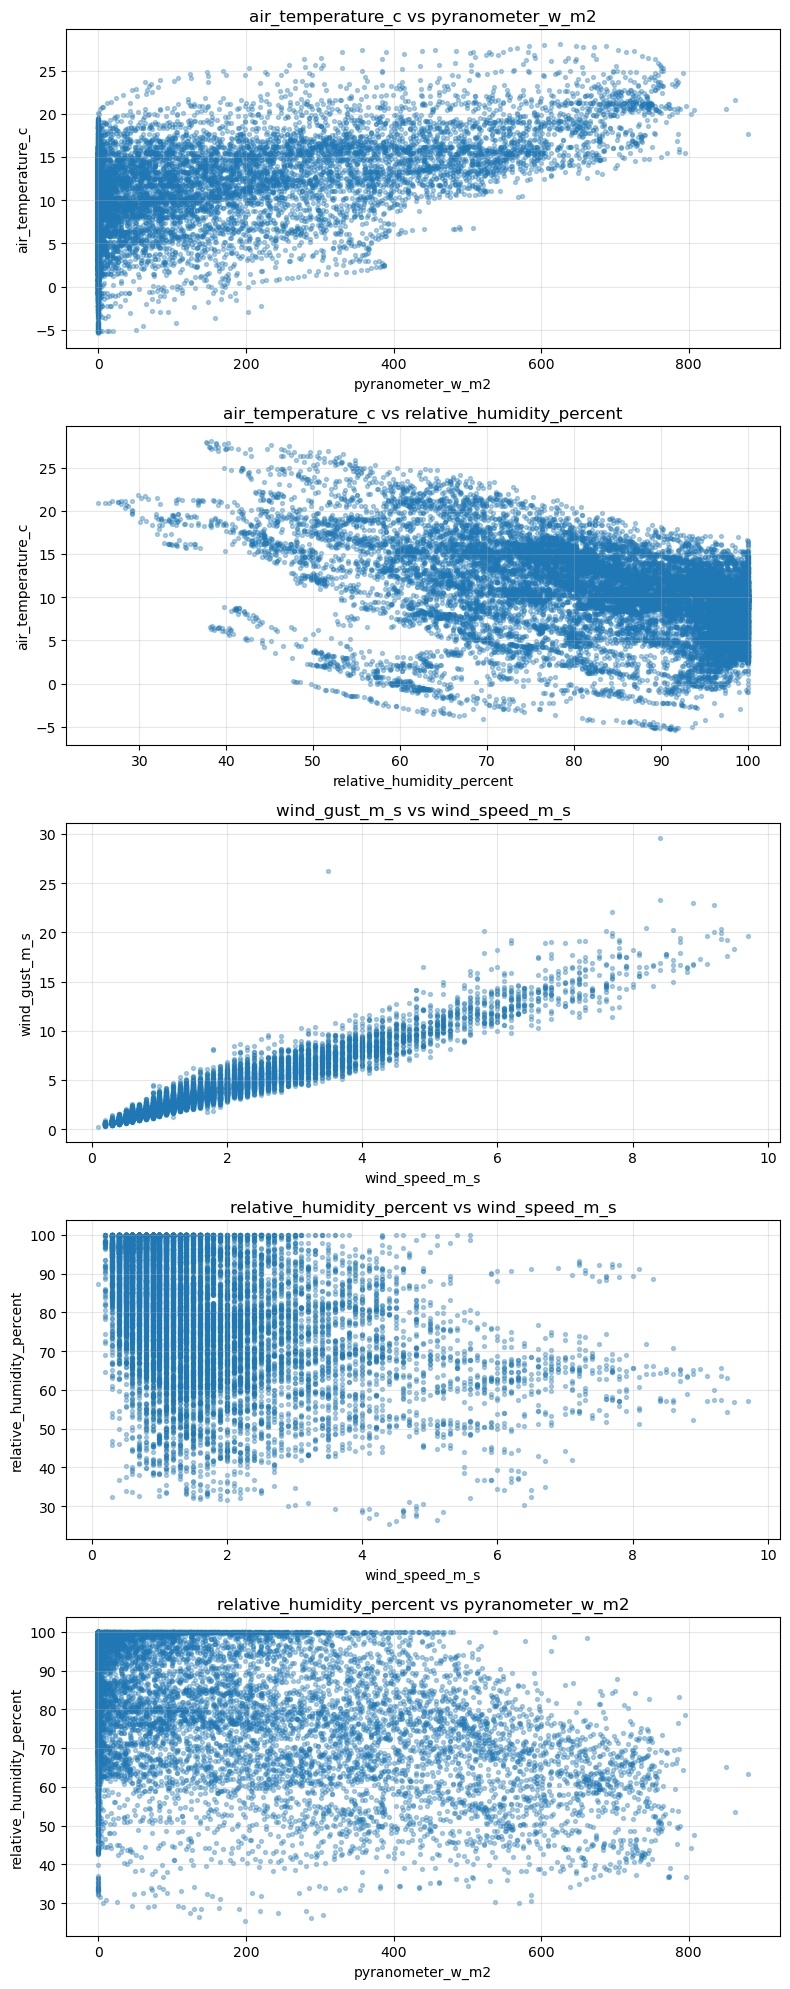

In [33]:
relationship_pairs = [
    ("pyranometer_w_m2", "air_temperature_c"),
    ("relative_humidity_percent", "air_temperature_c"),
    ("wind_speed_m_s", "wind_gust_m_s"),
    ("wind_speed_m_s", "relative_humidity_percent"),
    ("pyranometer_w_m2", "relative_humidity_percent"),
]

fig, axes = plt.subplots(len(relationship_pairs), 1, figsize=(8, 4 * len(relationship_pairs)))

for ax, (x_col, y_col) in zip(axes, relationship_pairs):
    ax.scatter(df[x_col], df[y_col], s=8, alpha=0.35)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f"{y_col} vs {x_col}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Notes For First Report

Fill this in after running the cells above.

### Dataset overview
- Rows:
- Date range:
- Sampling interval:
- Sensors available:

### Data quality observations
- Missing values:
- Duplicate timestamps:
- Physically impossible values:
- Sensor issues/dropouts:

### Time-series observations
- Temperature:
- Humidity:
- Solar radiation:
- Wind:
- Precipitation/strikes:

### Correlation observations
- Strong positive relationships:
- Strong negative relationships:
- Relationships that surprised me:

### Modeling implications for later
- Possible prediction target:
- Possible forecast horizon:
- Cleaning needed before modeling: